# 13. A Binary Dropout Model for Early Warning

Notebook 10 built an early-warning flag from the **three-class** models: flag a student when their predicted `P(Dropout)` is high. Notebook 11 showed that, at enrollment, Enrolled students look much more like graduates than like dropouts, which suggests a simpler setup: **train the model on Dropout vs. not** (Enrolled and Graduate pooled).

**Questions**
1. Does a model trained directly on Dropout vs. not rank at-risk students better than the three-class model's `P(Dropout)`? (13.2)
2. If advisors can only contact a fixed share of students, how many eventual dropouts does each approach catch? (13.3)
3. Are the predicted risks **calibrated**, i.e. does a predicted risk of 0.3 mean about 30% of those students drop out? Does recalibration fix it? (13.4)

**Evaluation rules:** same stratified 80/20 split as every other notebook (`random_state=42`). Everything here uses **5-fold cross-validation on the training portion only**; the holdout set is not touched. Notebook 14 evaluates the final model on the holdout set once. Only the two early stages are used (**Day 1** and **After Semester 1**), since a warning after Semester 2 comes too late to act on.

## 13.0 Setup

In [1]:
import sys
from pathlib import Path

cwd = Path.cwd()
ROOT = next((p for p in (cwd, *cwd.parents) if (p / "src" / "preprocessing.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the project root or its notebooks/ directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from scipy import stats
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight

from src.models import get_logistic_regression, get_random_forest, get_xgboost
from src.plotting import MODEL_ORDER, MODEL_PALETTE
from src.preprocessing import TARGET_COL, build_model_pipeline, get_feature_availability_sets, load_data

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
N_FOLDS = 5
CLASSES = ["Dropout", "Enrolled", "Graduate"]
STAGES = ["Day 1", "After Semester 1"]
APPROACHES = ["Three-class P(Dropout)", "Binary Dropout vs. not"]
APPROACH_STYLE = {"Three-class P(Dropout)": "--", "Binary Dropout vs. not": "-"}
CAPACITIES = [0.10, 0.20, 0.30, 0.40]
FIG_DIR = ROOT / "reports" / "figures"
OUT_DIR = ROOT / "data" / "processed"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = load_data()
feature_sets = get_feature_availability_sets(df)
y_all = df[TARGET_COL]
train_idx, test_idx = train_test_split(df.index.to_numpy(), test_size=0.20,
                                       random_state=RANDOM_STATE, stratify=y_all)
y_train = y_all.loc[train_idx]
is_dropout = (y_train == "Dropout").astype(int)
print(f"Training students: {len(train_idx)} | Dropout share: {is_dropout.mean():.1%} "
      f"| holdout ({len(test_idx)}) not used in this notebook")

Training students: 3539 | Dropout share: 32.1% | holdout (885) not used in this notebook


## 13.1 Out-of-fold dropout risk for every model and approach

For each stage and model, two versions are trained on the same 5 folds:

- **Three-class:** the existing models (balanced class weights), using the predicted `P(Dropout)` as the risk score. This is notebook 10's approach.
- **Binary:** the same model and settings, trained on Dropout vs. not (balanced class weights, so dropouts and non-dropouts count equally).

Every student in the training portion gets a risk score from a model that **didn't see them** (out-of-fold), so all comparisons below are fair. Scores are also kept per fold, so the two approaches can be compared fold by fold.

In [3]:
MODELS = {
    "Logistic Regression": (get_logistic_regression, True),
    "Random Forest": (get_random_forest, False),
    "XGBoost": (get_xgboost, False),
}


def make_pipeline(model_name, cols, binary):
    factory, scale = MODELS[model_name]
    model = factory(RANDOM_STATE)
    if model_name == "XGBoost" and binary:
        model = clone(model).set_params(eval_metric="logloss")
    return build_model_pipeline(model=model, feature_cols=cols, scale_numeric=scale)


def fit_risk(model_name, cols, X_fit, y_fit, X_eval, binary):
    """Fit one model and return P(Dropout) for X_eval."""
    pipe = make_pipeline(model_name, cols, binary)
    if binary:
        target = (y_fit == "Dropout").astype(int).to_numpy()
    else:
        target = LabelEncoder().fit(CLASSES).transform(y_fit) if model_name == "XGBoost" else y_fit
    fit_kw = {}
    if model_name == "XGBoost":
        fit_kw["model__sample_weight"] = compute_sample_weight("balanced", target)
    pipe.fit(X_fit, target, **fit_kw)
    proba = pipe.predict_proba(X_eval)
    classes = list(pipe.named_steps["model"].classes_)
    positive = 1 if binary else (0 if model_name == "XGBoost" else "Dropout")   # XGBoost encodes Dropout as 0
    return proba[:, classes.index(positive)]


cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
folds = list(cv.split(train_idx, y_train))

oof = {}          # (stage, model, approach) -> Series of out-of-fold P(Dropout)
fold_rows = []    # per-fold ranking metrics, for paired comparison
for stage in STAGES:
    cols = feature_sets[stage]
    X = df.loc[train_idx, cols]
    for model_name in MODELS:
        for approach in APPROACHES:
            binary = approach.startswith("Binary")
            scores = pd.Series(np.nan, index=X.index)
            for k, (fit_pos, val_pos) in enumerate(folds):
                X_fit, X_val = X.iloc[fit_pos], X.iloc[val_pos]
                risk = fit_risk(model_name, cols, X_fit, y_train.iloc[fit_pos], X_val, binary)
                scores.iloc[val_pos] = risk
                truth = is_dropout.iloc[val_pos]
                fold_rows.append({"Stage": stage, "Model": model_name, "Approach": approach, "Fold": k,
                                  "Average precision": average_precision_score(truth, risk),
                                  "ROC AUC": roc_auc_score(truth, risk)})
            assert scores.notna().all()
            oof[(stage, model_name, approach)] = scores
        print(f"done: {stage} | {model_name}")

fold_metrics = pd.DataFrame(fold_rows)

done: Day 1 | Logistic Regression
done: Day 1 | Random Forest
done: Day 1 | XGBoost
done: After Semester 1 | Logistic Regression
done: After Semester 1 | Random Forest
done: After Semester 1 | XGBoost


## 13.2 Does training on Dropout vs. not rank students better?

Two threshold-free measures of how well the risk score **ranks** students (higher = better):

- **Average precision (AP):** summarizes the precision-recall curve. A random ranking scores the dropout share (about 0.32).
- **ROC AUC:** the chance that a randomly chosen dropout gets a higher risk score than a randomly chosen non-dropout. Random = 0.5.

The paired test compares the two approaches on the same 5 folds (Nadeau-Bengio corrected t-test, which accounts for the folds sharing training data).

In [4]:
def corrected_t_p(diff, test_frac=1 / N_FOLDS):
    k = len(diff)
    var = np.var(diff, ddof=1) * (1 / k + test_frac / (1 - test_frac))
    if var == 0:
        return np.nan
    return 2 * stats.t.sf(abs(diff.mean() / np.sqrt(var)), k - 1)


summary = (fold_metrics.groupby(["Stage", "Model", "Approach"])[["Average precision", "ROC AUC"]]
           .agg(["mean", "std"]))
summary.columns = [f"{m} ({s})" for m, s in summary.columns]
summary = summary.reindex(pd.MultiIndex.from_product([STAGES, MODEL_ORDER, APPROACHES]))
display(summary.round(3))

paired = []
for stage in STAGES:
    for model_name in MODEL_ORDER:
        sub = fold_metrics[(fold_metrics["Stage"] == stage) & (fold_metrics["Model"] == model_name)]
        piv = sub.pivot(index="Fold", columns="Approach")
        row = {"Stage": stage, "Model": model_name}
        for metric in ["Average precision", "ROC AUC"]:
            diff = (piv[(metric, APPROACHES[1])] - piv[(metric, APPROACHES[0])]).to_numpy()
            row[f"Δ {metric} (binary − three-class)"] = diff.mean()
            row[f"p ({metric})"] = corrected_t_p(diff)
            row[f"Folds binary better ({metric})"] = f"{int((diff > 0).sum())}/{len(diff)}"
        paired.append(row)
paired = pd.DataFrame(paired)
display(paired.round(4))

summary.to_csv(OUT_DIR / "binary_vs_multiclass_cv.csv")

Average precision (mean)  \
Day 1            Logistic Regression Three-class P(Dropout)                     0.726   
                                     Binary Dropout vs. not                     0.734   
                 Random Forest       Three-class P(Dropout)                     0.725   
                                     Binary Dropout vs. not                     0.723   
                 XGBoost             Three-class P(Dropout)                     0.738   
                                     Binary Dropout vs. not                     0.740   
After Semester 1 Logistic Regression Three-class P(Dropout)                     0.853   
                                     Binary Dropout vs. not                     0.855   
                 Random Forest       Three-class P(Dropout)                     0.852   
                                     Binary Dropout vs. not                     0.849   
                 XGBoost             Three-class P(Dropout)                     0.860   
                                     Binary Dropout vs. not                     0.860   

                                                             Average precision (std)  \
Day 1            Logistic Regression Three-class P(Dropout)                    0.023   
                                     Binary Dropout vs. not                    0.028   
                 Random Forest       Three-class P(Dropout)                    0.020   
                                     Binary Dropout vs. not                    0.022   
                 XGBoost             Three-class P(Dropout)                    0.012   
                                     Binary Dropout vs. not                    0.020   
After Semester 1 Logistic Regression Three-class P(Dropout)                    0.021   
                                     Binary Dropout vs. not                    0.022   
                 Random Forest       Three-class P(Dropout)                    0.022   
                                     Binary Dropout vs. not                    0.024   
                 XGBoost             Three-class P(Dropout)                    0.014   
                                     Binary Dropout vs. not                    0.018   

                                                             ROC AUC (mean)  \
Day 1            Logistic Regression Three-class P(Dropout)           0.813   
                                     Binary Dropout vs. not           0.821   
                 Random Forest       Three-class P(Dropout)           0.817   
                                     Binary Dropout vs. not           0.819   
                 XGBoost             Three-class P(Dropout)           0.818   
                                     Binary Dropout vs. not           0.821   
After Semester 1 Logistic Regression Three-class P(Dropout)           0.899   
                                     Binary Dropout vs. not           0.902   
                 Random Forest       Three-class P(Dropout)           0.898   
                                     Binary Dropout vs. not           0.897   
                 XGBoost             Three-class P(Dropout)           0.900   
                                     Binary Dropout vs. not           0.902   

                                                             ROC AUC (std)  
Day 1            Logistic Regression Three-class P(Dropout)          0.011  
                                     Binary Dropout vs. not          0.013  
                 Random Forest       Three-class P(Dropout)          0.016  
                                     Binary Dropout vs. not          0.016  
                 XGBoost             Three-class P(Dropout)          0.007  
                                     Binary Dropout vs. not          0.012  
After Semester 1 Logistic Regression Three-class P(Dropout)          0.017  
                                     Binary Dropout vs. not          0.017  
                 Random Forest       

,Stage,Model,Δ Average precision (binary − three-class),p (Average precision),Folds binary better (Average precision),Δ ROC AUC (binary − three-class),p (ROC AUC),Folds binary better (ROC AUC)
0,Day 1,Logistic Regression,0.0078,0.4291,4/5,0.0081,0.0821,5/5
1,Day 1,Random Forest,-0.0014,0.6048,1/5,0.0020,0.2525,4/5
2,Day 1,XGBoost,0.0017,0.8728,3/5,0.0035,0.4375,3/5
3,After Semester 1,Logistic Regression,0.0026,0.4718,3/5,0.0030,0.1183,4/5
4,After Semester 1,Random Forest,-0.0025,0.4302,1/5,-0.0016,0.5766,1/5
5,After Semester 1,XGBoost,0.0007,0.9064,3/5,0.0018,0.6074,3/5


**Reading 13.2: no, training on Dropout vs. not doesn't rank students better.**

- The differences are tiny: average precision and ROC AUC change by at most ±0.008, none of the differences is significant (every p ≥ 0.08), and the binary model wins in only about half of the folds.
- **The model barely matters either:** average precision is 0.72–0.74 for all three models at Day 1 and 0.85–0.86 after Semester 1.
- **What matters is the information stage:** Semester 1 data adds about 0.12 average precision for every model and approach, the same pattern as notebooks 07 and 08.

Why: the three-class models already learn what separates dropouts from everyone else, and also learning to split Enrolled from Graduate doesn't hurt that. So pooling is justified by what the question means (notebook 11), not because it improves the ranking. We still recommend the **binary model for the early-warning tool**: it answers the actual question ("will this student drop out?"), it gives one risk score, and it performs just as well.

## 13.3 Capacity-based warning: what if advisors can only contact X% of students?

Notebook 10 picked thresholds that flagged about half of all students. A school usually has a **fixed outreach capacity** instead, so the practical question is: *if we contact the top X% of students by predicted risk, what share of eventual dropouts do we reach?*

For each capacity, students are ranked by their out-of-fold risk and the top X% are flagged.

- **Recall** = share of all dropouts who were flagged.
- **Precision** = share of flagged students who did drop out.
- **Lift** = precision ÷ the overall dropout share (how much better than contacting students at random).

In [5]:
def capacity_stats(scores, truth, capacity):
    n_flag = round(capacity * len(scores))
    flagged = scores.rank(method="first", ascending=False) <= n_flag
    tp = int((flagged & (truth == 1)).sum())
    precision = tp / n_flag
    return {"Students contacted": f"{capacity:.0%}", "Recall": tp / truth.sum(),
            "Precision": precision, "Lift": precision / truth.mean(), "Dropouts reached": tp,
            "Dropouts missed": int(truth.sum()) - tp}


cap_rows = []
for (stage, model_name, approach), scores in oof.items():
    for c in CAPACITIES:
        cap_rows.append({"Stage": stage, "Model": model_name, "Approach": approach,
                         **capacity_stats(scores, is_dropout.loc[scores.index], c)})
capacity = pd.DataFrame(cap_rows)
capacity.to_csv(OUT_DIR / "binary_capacity_cv.csv", index=False)

recall_wide = capacity.pivot_table(index=["Stage", "Model"], columns=["Students contacted", "Approach"],
                                   values="Recall").reindex(pd.MultiIndex.from_product([STAGES, MODEL_ORDER]))
print("Share of dropouts reached (out-of-fold, training portion):")
display(recall_wide.style.format("{:.1%}"))

Share of dropouts reached (out-of-fold, training portion):


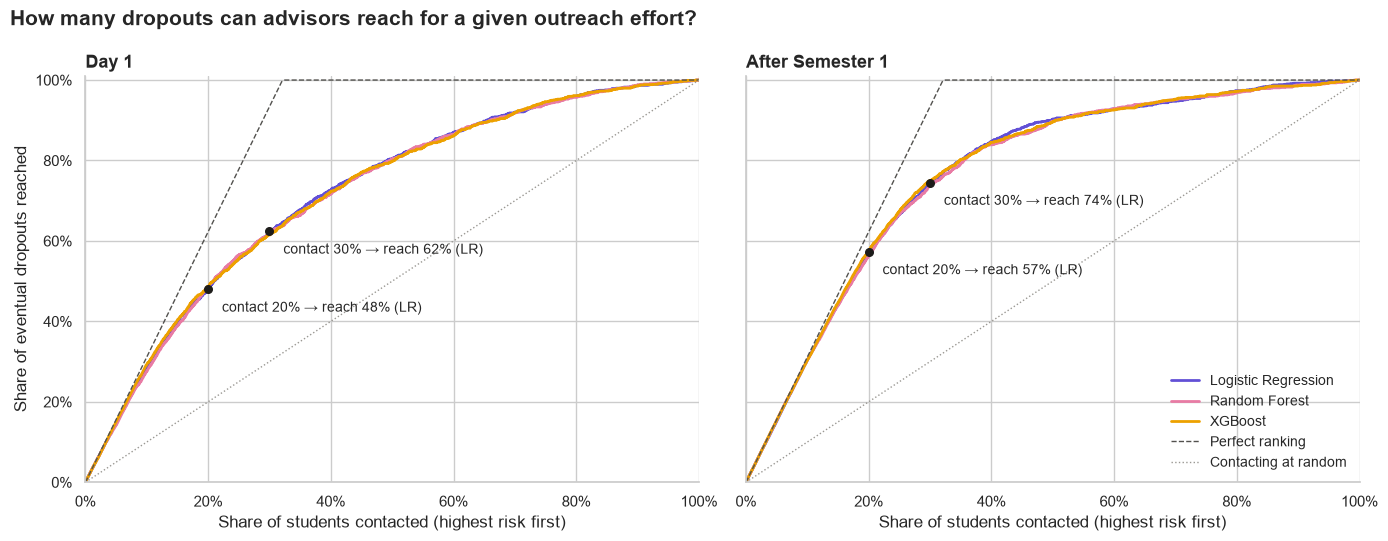

In [6]:
# The three-class and binary curves lie on top of each other (see the table above),
# so the chart shows the binary models only, plus the best possible ranking for reference.
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
rate = is_dropout.mean()
xs_ref = np.linspace(0, 1, 201)
for ax, stage in zip(axes, STAGES):
    for model_name in MODEL_ORDER:
        s = oof[(stage, model_name, APPROACHES[1])]
        truth = is_dropout.loc[s.index].to_numpy()[np.argsort(-s.to_numpy(), kind="stable")]
        caught = np.concatenate([[0], np.cumsum(truth)]) / truth.sum()
        ax.plot(np.arange(len(caught)) / (len(caught) - 1), caught, color=MODEL_PALETTE[model_name],
                lw=2, label=model_name)
    ax.plot(xs_ref, np.minimum(xs_ref / rate, 1), color="#52514e", lw=1, ls="--", label="Perfect ranking")
    ax.plot([0, 1], [0, 1], color="#9a9893", lw=1, ls=":", label="Contacting at random")
    for c in [0.2, 0.3]:
        r = capacity[(capacity["Stage"] == stage) & (capacity["Model"] == "Logistic Regression")
                     & (capacity["Approach"] == APPROACHES[1]) & (capacity["Students contacted"] == f"{c:.0%}")]
        recall = r["Recall"].iloc[0]
        ax.scatter([c], [recall], color="#1d1c1a", s=30, zorder=5)
        ax.annotate(f"contact {c:.0%} → reach {recall:.0%} (LR)", (c, recall), xytext=(10, -16),
                    textcoords="offset points", fontsize=10)
    ax.set_title(stage, fontsize=13, fontweight="bold", loc="left")
    ax.set_xlabel("Share of students contacted (highest risk first)")
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.01)
axes[0].set_ylabel("Share of eventual dropouts reached")
axes[1].legend(loc="lower right", fontsize=10, frameon=False)
fig.suptitle("How many dropouts can advisors reach for a given outreach effort?", x=0.01, ha="left",
             fontsize=15, fontweight="bold")
sns.despine()
plt.tight_layout()
plt.savefig(FIG_DIR / "binary_capacity_gain_curves.png", dpi=200, bbox_inches="tight")
plt.show()

**Reading 13.3:**

| Contact the top… | Day 1: dropouts reached | Day 1: share of contacted who drop out | After Sem 1: dropouts reached | After Sem 1: share of contacted who drop out |
|---|---|---|---|---|
| 10% | 29% | 93% | 30% | 98% |
| 20% | 48% | 77% | 57% | 92% |
| 30% | 62% | 67% | 75% | 80% |
| 40% | 73% | 58% | 85% | 68% |

(Logistic regression, binary; the other models are within about 1–2 points.)

- **After Semester 1, contacting the top 20% of students reaches 57% of eventual dropouts**, and 92% of the students contacted really do drop out. That's about 2.9 times better than contacting students at random.
- **At 10%, the models are close to perfect.** Only 32% of students drop out, so the most a 10% list can reach is 31% of them; the models reach 29–30%.
- **On Day 1 it's still useful:** the top 20% reaches about half of eventual dropouts, with 77% of them dropping out.
- **Compared with notebook 10,** whose thresholds flagged 50–59% of students at about 50% precision, a capacity rule gives advisors a much shorter and more accurate list. The trade-off is that more dropouts are missed, and how many students to contact is the school's decision, not the model's.
- These are out-of-fold estimates on the training portion. Notebook 14 checks the final model on the holdout set once.

## 13.4 Are the predicted risks calibrated?

Balanced class weights make the model treat dropouts and non-dropouts as equally common during training, which is good for ranking but **inflates the predicted risk**. If the score is going to be shown to advisors as a probability ("this student has a 60% risk"), it needs to be calibrated.

Below:

- **Reliability curve:** students are grouped by predicted risk, and each group's actual dropout rate is plotted against its average prediction. A calibrated model sits on the diagonal.
- **Brier score:** mean squared error of the predicted probability (lower is better). For reference, predicting the overall dropout share for everyone scores about 0.22.
- **Recalibration:** the binary model is wrapped in `CalibratedClassifierCV` (isotonic, 3 inner folds), fit inside each outer training fold, so the calibration never sees the students it's scored on. Recalibration changes the probabilities but should barely change the ranking.

Brier score of predicting 32.1% for everyone: 0.218


,Stage,Risk score,Brier score,Mean predicted risk,Actual dropout share,Average precision,ROC AUC
0,Day 1,Three-class P(Dropout),0.153,0.322,0.321,0.724,0.812
1,Day 1,"Binary, balanced weights",0.166,0.434,0.321,0.732,0.821
2,Day 1,"Binary, recalibrated",0.149,0.321,0.321,0.729,0.819
3,After Semester 1,Three-class P(Dropout),0.108,0.310,0.321,0.852,0.898
4,After Semester 1,"Binary, balanced weights",0.115,0.401,0.321,0.854,0.901
5,After Semester 1,"Binary, recalibrated",0.105,0.321,0.321,0.850,0.900


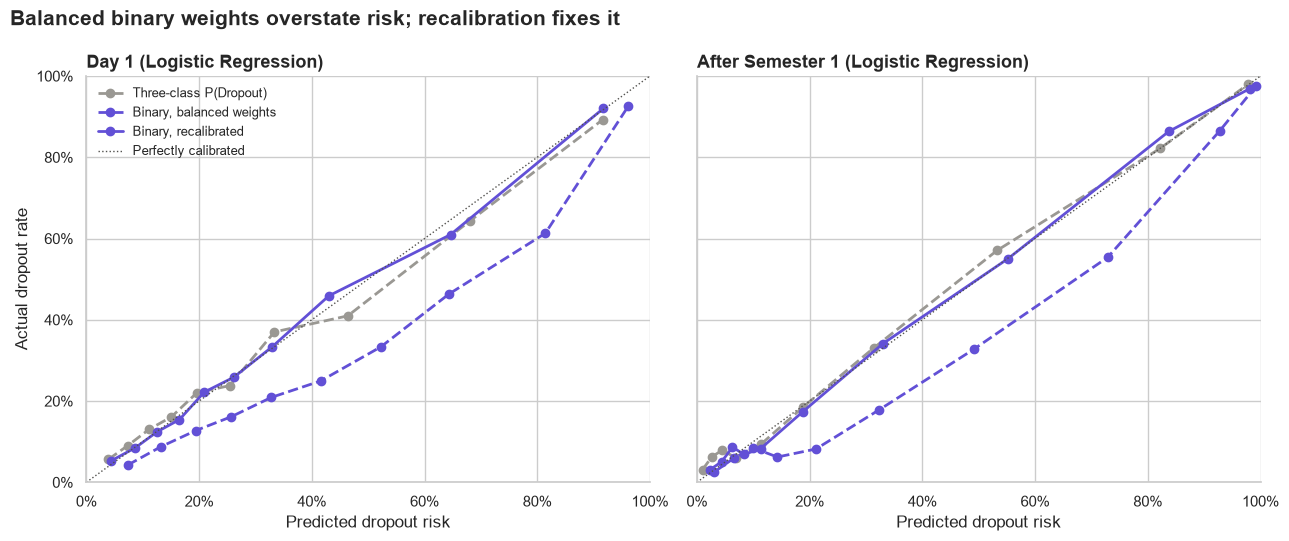

In [7]:
CAL_MODEL = "Logistic Regression"   # the interpretable choice (RF also works; XGBoost would need its sample weights)


def fit_calibrated_risk(model_name, cols, X_fit, y_fit, X_eval):
    pipe = make_pipeline(model_name, cols, binary=True)
    calibrated = CalibratedClassifierCV(pipe, method="isotonic", cv=3)
    calibrated.fit(X_fit, (y_fit == "Dropout").astype(int).to_numpy())
    return calibrated.predict_proba(X_eval)[:, 1]


cal_scores = {}
for stage in STAGES:
    cols = feature_sets[stage]
    X = df.loc[train_idx, cols]
    s = pd.Series(np.nan, index=X.index)
    for fit_pos, val_pos in folds:
        s.iloc[val_pos] = fit_calibrated_risk(CAL_MODEL, cols, X.iloc[fit_pos], y_train.iloc[fit_pos],
                                              X.iloc[val_pos])
    cal_scores[stage] = s

base_rate = is_dropout.mean()
cal_rows = []
for stage in STAGES:
    truth = is_dropout
    for label, s in [("Three-class P(Dropout)", oof[(stage, CAL_MODEL, APPROACHES[0])]),
                     ("Binary, balanced weights", oof[(stage, CAL_MODEL, APPROACHES[1])]),
                     ("Binary, recalibrated", cal_scores[stage])]:
        t = truth.loc[s.index]
        cal_rows.append({"Stage": stage, "Risk score": label,
                         "Brier score": brier_score_loss(t, s),
                         "Mean predicted risk": s.mean(), "Actual dropout share": t.mean(),
                         "Average precision": average_precision_score(t, s),
                         "ROC AUC": roc_auc_score(t, s)})
calibration = pd.DataFrame(cal_rows)
print(f"Brier score of predicting {base_rate:.1%} for everyone: {brier_score_loss(is_dropout, np.full(len(is_dropout), base_rate)):.3f}")
display(calibration.round(3))
calibration.to_csv(OUT_DIR / "binary_calibration_cv.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
styles = {"Three-class P(Dropout)": ("#9a9893", "--"), "Binary, balanced weights": (MODEL_PALETTE[CAL_MODEL], "--"),
          "Binary, recalibrated": (MODEL_PALETTE[CAL_MODEL], "-")}
for ax, stage in zip(axes, STAGES):
    for label, s in [("Three-class P(Dropout)", oof[(stage, CAL_MODEL, APPROACHES[0])]),
                     ("Binary, balanced weights", oof[(stage, CAL_MODEL, APPROACHES[1])]),
                     ("Binary, recalibrated", cal_scores[stage])]:
        frac, mean_pred = calibration_curve(is_dropout.loc[s.index], s, n_bins=10, strategy="quantile")
        color, ls = styles[label]
        ax.plot(mean_pred, frac, marker="o", color=color, ls=ls, lw=2, label=label)
    ax.plot([0, 1], [0, 1], color="#52514e", lw=1, ls=":", label="Perfectly calibrated")
    ax.set_title(f"{stage} ({CAL_MODEL})", fontsize=13, fontweight="bold", loc="left")
    ax.set_xlabel("Predicted dropout risk")
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
axes[0].set_ylabel("Actual dropout rate")
axes[0].legend(loc="upper left", frameon=False, fontsize=9)
fig.suptitle("Balanced binary weights overstate risk; recalibration fixes it", x=0.01, ha="left",
             fontsize=15, fontweight="bold")
sns.despine()
plt.tight_layout()
plt.savefig(FIG_DIR / "binary_calibration_curves.png", dpi=200, bbox_inches="tight")
plt.show()

**Reading 13.4:**

- **The three-class model's `P(Dropout)` is already roughly calibrated** (mean predicted risk 32% vs. 32% actual; Brier 0.153 at Day 1 and 0.108 after Semester 1). That's partly a coincidence of this dataset: balancing gives each of the three classes a weight of one third, which happens to be close to the real 32% dropout share.
- **The binary model with balanced weights overstates risk:** it predicts an average risk of 43% at Day 1 and 40% after Semester 1 when only 32% drop out, and its Brier score is worse (0.166 / 0.115).
- **Recalibration fixes it:** the average prediction drops to 32%, the Brier score becomes the best of the three (0.149 / 0.105), and the ranking is unchanged (average precision 0.729 vs. 0.732).
- All three versions beat the no-information baseline (Brier 0.218) by a wide margin.

**Practical meaning:** if advisors only need a ranked list, any version works. If the tool shows a risk as a percentage ("this student has a 70% chance of dropping out"), use the **recalibrated binary model** so that the number means what it says.

## 13.5 Answer

| Question | Finding |
|---|---|
| Does a binary Dropout-vs-not model rank students better? | **No measurable difference** from the three-class `P(Dropout)` (Δ average precision ≤ 0.008, all p ≥ 0.08). The model choice barely matters either; the information stage does (+0.12 average precision with Semester 1 data). |
| How many dropouts can a fixed outreach effort reach? | After Semester 1, contacting the **top 20%** of students reaches **57%** of eventual dropouts, and **92%** of those contacted drop out (2.9× better than random). Top 30%: 75% reached, 80% precision. On Day 1, the top 20% reaches 48%. |
| Are the risks calibrated? | Balanced weights make the binary model **overstate risk** (43% average vs. 32% actual). **Isotonic recalibration fixes it** without changing the ranking. |

**Recommendation for the early-warning tool:** a recalibrated binary Dropout-vs-not model, run after Semester 1, with the outreach list sized to advisors' capacity (for example the top 20–30%). It performs the same as the three-class model, but it answers the actual question, gives one calibrated risk score, and is easier to explain.

**Possible headline for the final presentation:** *"After Semester 1, contacting the 20% of students with the highest predicted risk reaches 57% of eventual dropouts, and 9 out of 10 students contacted would otherwise drop out."*

**Limitations:**

- All numbers here are out-of-fold estimates on the training portion. The holdout check belongs to notebook 14.
- The capacity rule ranks students against each other within a cohort. In practice, the cutoff score would be set from past cohorts.
- Recalibration was checked for logistic regression only.
- This is a single institution, and "dropout" is measured at the end of the normal course length, so later dropouts among Enrolled students are counted as not dropping out.

Outputs: `data/processed/binary_vs_multiclass_cv.csv`, `binary_capacity_cv.csv`, `binary_calibration_cv.csv`; figures `reports/figures/binary_capacity_gain_curves.png`, `binary_calibration_curves.png`.